# What patterns emerge when clustering Billboard No. 1 Hits?
*When Billboard Number 1 Hits are clustered using their documented music-industry characteristics,  how has the representation of these groups changed over time?*

**Source dataset:** [Billboard Hot 100 No. 1 recordings](https://docs.google.com/spreadsheets/d/1j1AUgtMnjpFTz54UdXgCKZ1i4bNxFjf01ImJ-BqBEt0/edit?gid=1974823090#gid=1974823090) (Compiled by Chris Dalla Riva).  



## 1. Load the data and import libraries


In [ ]:
%pip install -q pandas matplotlib numpy openpyxl kmodes

print('Packages installed.')

Packages installed.


In [ ]:
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from kmodes.kmodes import KModes

warnings.filterwarnings(
    'ignore',
    message=r'The resize_event function was deprecated.*',
    category=matplotlib.MatplotlibDeprecationWarning,
)

np.random.seed(42)
pd.set_option('display.max_columns', 30)
print('Libraries imported.')

Libraries imported.


In [ ]:
file_path = Path('hits db.xlsx')
if not file_path.exists():
    try:
        from google.colab import files
        print('Upload hits db.xlsx')
        uploaded = files.upload()
        file_path = Path(next(iter(uploaded)))
    except ImportError as exc:
        raise FileNotFoundError('Place hits db.xlsx beside the notebook.') from exc

df = pd.read_excel(file_path, sheet_name='Data')

print('Original dataset shape:', df.shape)
display(df[['Song', 'Artist', 'Date', 'Discogs Genre',
            'Artist Place of Origin', 'Parent Label']].head())

Upload hits db.xlsx


Saving hits db.xlsx to hits db.xlsx
Original dataset shape: (1177, 105)


,Song,Artist,Date,Discogs Genre,Artist Place of Origin,Parent Label
0,Poor Little Fool,Ricky Nelson,1958-08-04,Rock,United States,Imperial
1,Nel Blu Dipinto Di Blu,Domenico Modugno,1958-08-18,"Pop;Folk, World, & Country",Italy,Decca
2,Little Star,The Elegants,1958-08-25,Rock,United States,ABC
3,It's All in the Game,Tommy Edwards,1958-09-29,Rock;Pop,United States,MGM
4,It's Only Make Believe,Conway Twitty,1958-11-10,Rock,United States,MGM


## 2. Data cleaning

I selected six inputs that describe **genre, artist origin, corporate affiliation, artist configuration, and the artist's participation in songwriting and production**.

In [ ]:
# preserve all original fields and create derived columns within the same df.
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df['year'] = df['Date'].dt.year
df['decade'] = (df['year'] // 10 * 10).astype('Int64').astype(str) + 's'

#selecting feature cols from dataset
categorical_cols = [
    'Discogs Genre',
    'Artist Place of Origin',
    'Parent Label',
    'Artist Structure',
    'Artist is a Songwriter',
    'Artist is a Producer',
]

# checking missing data and most common values for each column
audit = pd.DataFrame({
    'available': df[categorical_cols].notna().sum(),
    'missing': df[categorical_cols].isna().sum(),
    'unique_categories': df[categorical_cols].nunique(dropna=True),
})
display(audit)

for col in categorical_cols:
    print(f'\n{col}: most common source values')
    display(df[col].value_counts(dropna=False).head(6))

,available,missing,unique_categories
Discogs Genre,1161,16,74
Artist Place of Origin,1177,0,60
Parent Label,1175,2,132
Artist Structure,1177,0,6
Artist is a Songwriter,1177,0,2
Artist is a Producer,1173,4,2



Discogs Genre: most common source values


,count
Discogs Genre,
Rock,232
Rock;Pop,132
Funk/Soul,125
Hip Hop,113
Pop,103
Electronic;Pop,71



Artist Place of Origin: most common source values


,count
Artist Place of Origin,
United States,837
United Kingdom,170
Canada,39
United States;United Kingdom,15
Australia,13
United States;Canada,9


...

,count
Artist Structure,
1.0,578
0.0,399
1.5,92
2.0,89
0.5,11
2.5,8



Artist is a Songwriter: most common source values


,count
Artist is a Songwriter,
1,771
0,406



Artist is a Producer: most common source values


,count
Artist is a Producer,
0.0,776
1.0,397
NaN,4


In [ ]:
X = df[categorical_cols].copy()
for col in categorical_cols:
    X[col] = X[col].astype('string').str.strip()
    X[col] = X[col].replace({'': pd.NA})

# missing categories are unknown they are not another category.
missing_by_row = X.isna().any(axis=1)
X = X.loc[~missing_by_row].astype(str)

print('Songs available for clustering:', len(X))
print('Songs excluded because a model field was missing:', missing_by_row.sum())
display(X.head())

# do the missing calues remove particular decades.
coverage = pd.crosstab(df['decade'], missing_by_row).reindex(columns=[False, True], fill_value=0)
coverage.columns = ['included', 'excluded']
coverage['excluded_pct'] = (100 * coverage['excluded'] /
                            (coverage['included'] + coverage['excluded'])).round(1)
display(coverage)

Songs available for clustering: 1155
Songs excluded because a model field was missing: 22


,Discogs Genre,Artist Place of Origin,Parent Label,Artist Structure,Artist is a Songwriter,Artist is a Producer
0,Rock,United States,Imperial,1.0,0,1.0
3,Rock;Pop,United States,MGM,1.0,0,0.0
4,Rock,United States,MGM,1.0,1,0.0
5,"Folk, World, & Country",United States,EMI,0.0,0,0.0
6,Pop,United States,Dore,0.0,1,1.0


,included,excluded,excluded_pct
decade,,,
1950s,20,3,13.0
1960s,202,1,0.5
1970s,253,0,0.0
1980s,231,0,0.0
1990s,139,1,0.7
2000s,129,0,0.0
2010s,116,0,0.0
2020s,65,17,20.7


## 3. Choosing the number of clusters

I used the elbow method to help pick the clusters I chose to use in my analysis. Although the elbow suggested 4 clusters, I saw another large reduction between 6 and 7 and chose to test the model using both 4 and 7 clusters.

In [ ]:
cost = []
k_range = range(1, 9)

for k in k_range:
    # 'Cao' initialization is highly recommended over random for K-Modes.
    km = KModes(n_clusters=k, init='Cao', n_init=1, verbose=0)
    km.fit(X)
    cost.append(km.cost_)  # Cost = total number of feature mismatches (Hamming distance).

print('Clustering cost for k = 1 to 8:')
for k_value, score in zip(k_range, cost):
    print(f'k={k_value}: cost={score:.0f}')

# The knee heuristic is fixed before looking at cluster membership.
k_values = np.asarray(list(k_range), dtype=float)
cost_values = np.asarray(cost, dtype=float)
x_axis = (k_values - k_values.min()) / (k_values.max() - k_values.min())
y_axis = (cost_values - cost_values.min()) / (cost_values.max() - cost_values.min())
line = 1 - x_axis
knee_distance = line - y_axis
knee_distance[0] = knee_distance[-1] = -np.inf
k = int(k_values[np.argmax(knee_distance)])

print('Suggested k from the elbow:', k)
elbow_k = k


Clustering cost for k = 1 to 8:
k=1: cost=3662
k=2: cost=3317
k=3: cost=3101
k=4: cost=2775
k=5: cost=2701
k=6: cost=2697
k=7: cost=2436
k=8: cost=2372
Suggested k from the elbow heuristic: 4


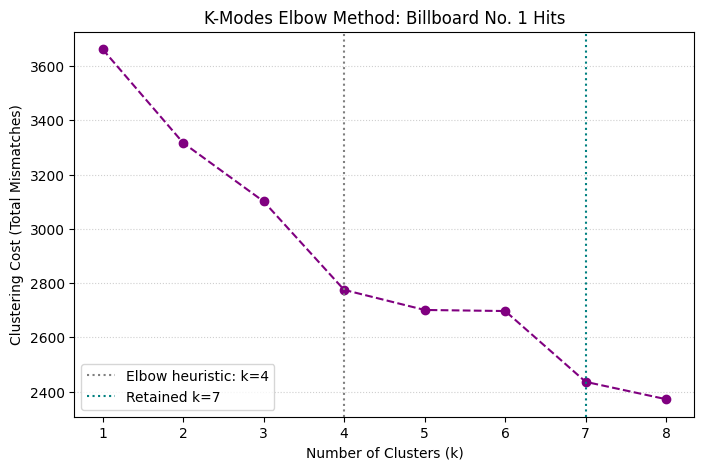

In [ ]:
# elbow plot
plt.figure(figsize=(8, 5))
plt.plot(k_range, cost, marker='o', linestyle='--', color='purple')
plt.axvline(elbow_k, color='gray', linestyle=':', label=f'Elbow heuristic: k={elbow_k}')
plt.axvline(7, color='teal', linestyle=':', label='Retained k=7')
plt.title('K-Modes Elbow Method: Billboard No. 1 Hits')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Clustering Cost (Total Mismatches)')
plt.xticks(k_range)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.legend()
plt.show()

## 4. Run the seven-cluster K-Modes model

As in the professor's example, fit the final model, assign each observation to a cluster, and examine the **cluster modes**. Seven was retained after inspecting the cost curve and comparing it against the four-cluster benchmark. The clusters are not predefined artist, genre, or record-label classes. Because the modal value of a field may be held by a minority of observations, the next section also reports its share within the cluster.

Most Frequent Categories


,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster 5,Cluster 6,Cluster 7
Discogs Genre,Rock,Hip Hop,Rock,Funk/Soul,Pop,Rock;Pop,Rock;Pop
Artist Place of Origin,United States,United States,United Kingdom,United States,United States,United States,United States
Parent Label,Sony,Warner Bros.,Warner Bros.,Motown,CBS,Vivendi,CBS
Artist Structure,1.0,0.0,0.0,0.0,2.0,0.0,1.0
Artist is a Songwriter,1,1,1,0,1,1,0
Artist is a Producer,0.0,1.0,0.0,0.0,1.0,0.0,0.0


,songs,share_of_clustered_hits_pct
cluster,,
1,416,36.0
2,194,16.8
3,105,9.1
4,170,14.7
5,57,4.9
6,62,5.4
7,151,13.1


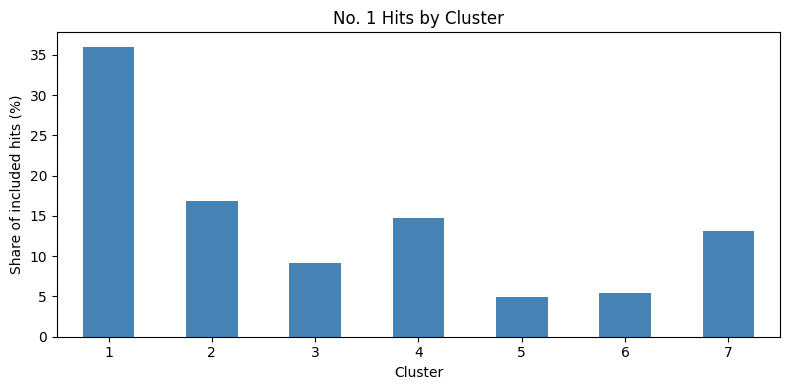

In [ ]:
# main analysis is seven clusters; the 4 cluster model is a benchmark.
k = 7
final_km = KModes(n_clusters=k, init='Cao', n_init=1, verbose=0)
clusters = final_km.fit_predict(X)

# saving original row indices so assignments join back to the original dataset.
df['cluster'] = pd.Series(clusters + 1, index=X.index, dtype='Int64')

print('Most Frequent Categories')
centroids_df = pd.DataFrame(final_km.cluster_centroids_, columns=X.columns)
centroids_df.index = [f'Cluster {i}' for i in range(1, k + 1)]
display(centroids_df.T)

sizes = df['cluster'].value_counts().sort_index()
cluster_sizes = pd.DataFrame({
    'songs': sizes,
    'share_of_clustered_hits_pct': (sizes / len(X) * 100).round(1),
})
display(cluster_sizes)

ax = cluster_sizes['share_of_clustered_hits_pct'].plot.bar(figsize=(8, 4), color='steelblue')
ax.set_title('No. 1 Hits by Cluster')
ax.set_xlabel('Cluster')
ax.set_ylabel('Share of included hits (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# top  categories within each cluster.
profiles = []
for cluster_id in range(1, k + 1):
    subset = X.loc[df.index[df['cluster'] == cluster_id]]
    mode = centroids_df.loc[f'Cluster {cluster_id}']
    row = {'cluster': cluster_id, 'songs': len(subset)}
    for col in categorical_cols:
        row[col + ' mode'] = mode[col]
        row[col + ' mode %'] = round(100 * (subset[col] == mode[col]).mean(), 1)
    profiles.append(row)
profile = pd.DataFrame(profiles).set_index('cluster')
print('Source category modes and percentage matching the mode:')
display(profile.T)

# songs closest to each centerpoint.
for cluster_id in range(1, k + 1):
    rows = X.index[df.loc[X.index, 'cluster'] == cluster_id]
    mode = centroids_df.loc[f'Cluster {cluster_id}']
    mismatches = X.loc[rows].ne(mode).sum(axis=1)
    examples = (df.loc[rows, ['Song', 'Artist', 'year', 'Discogs Genre', 'Parent Label']]
                .assign(category_mismatches=mismatches)
                .sort_values(['category_mismatches', 'Song', 'Artist'])
                .head(5))
    print(f'\nCluster {cluster_id}: five recordings nearest the cluster mode')
    display(examples)

Source category modes and percentage matching the mode:


cluster,1,2,3,4,5,6,7
songs,416,194,105,170,57,62,151
Discogs Genre mode,Rock,Hip Hop,Rock,Funk/Soul,Pop,Rock;Pop,Rock;Pop
Discogs Genre mode %,26.4,23.7,60.0,41.8,36.8,35.5,23.8
Artist Place of Origin mode,United States,United States,United Kingdom,United States,United States,United States,United States
Artist Place of Origin mode %,74.3,72.2,80.0,90.6,70.2,77.4,81.5
Parent Label mode,Sony,Warner Bros.,Warner Bros.,Motown,CBS,Vivendi,CBS
Parent Label mode %,27.6,25.8,36.2,20.6,35.1,51.6,16.6
Artist Structure mode,1.0,0.0,0.0,0.0,2.0,0.0,1.0
Artist Structure mode %,79.3,61.9,83.8,71.2,66.7,50.0,94.0
Artist is a Songwriter mode,1,1,1,0,1,1,0



Cluster 1: five recordings nearest the cluster mode


,Song,Artist,year,Discogs Genre,Parent Label,category_mismatches
697,Toy Soldiers,Martika,1989,Rock,Sony,0
1038,All About that Bass,Meghan Trainor,2014,Reggae;Funk/Soul;Pop,Sony,1
265,American Pie,Don McLean,1972,Rock,Transamerica,1
331,Annie's Song,John Denver,1974,Rock,RCA,1
298,"Bad, Bad Leroy Brown",Jim Croce,1973,Rock,ABC,1



Cluster 2: five recordings nearest the cluster mode


...

,Song,Artist,year,Discogs Genre,Parent Label,category_mismatches
636,I Just Can't Stop Loving You,Michael Jackson & Siedah Garrett,1987,Pop,CBS,0
230,Bridge Over Troubled Water,Simon & Garfunkel,1970,"Pop;Folk, World, & Country",CBS,1
562,Careless Whisper,Wham!,1985,Pop,CBS,1
1176,Die with a Smile,Bruno Mars & Lady Gaga,2025,Pop,Universal,1
481,Do That to Me One More Time,Captain & Tennille,1980,Pop,Polygram,1



Cluster 6: five recordings nearest the cluster mode


,Song,Artist,year,Discogs Genre,Parent Label,category_mismatches
1084,Sucker,Jonas Brothers,2019,Rock;Pop,Vivendi,0
618,At This Moment,Billy Vera & the Beaters,1987,Rock;Pop,Rhino,1
80,Big Girls Don't Cry,Frankie Valli & the Four Seasons,1962,Rock;Pop,Vee-Jay,1
357,Black Water,The Doobie Brothers,1975,Rock;Pop,Warner Bros.,1
168,Cherish,The Association,1966,Rock;Pop,Valiant,1



Cluster 7: five recordings nearest the cluster mode


,Song,Artist,year,Discogs Genre,Parent Label,category_mismatches
311,The Most Beautiful Girl,Charlie Rich,1973,Rock;Pop,CBS,0
97,Blue Velvet,Bobby Vinton,1963,Pop;Stage & Screen,CBS,1
430,Da Doo Ron Ron,Shaun Cassidy,1977,Rock;Pop,Warner Bros.,1
319,Dark Lady,Cher,1974,Rock;Pop,MCA,1
392,Disco Lady,Johnnie Taylor,1976,Funk/Soul,CBS,1


## 5. Compare the four- and seven-cluster solutions

The elbow showed 4 as the ideal cluster size while I chose 7 due to the sudden dip between 6 and 7. I decided to compare the two cluster sizes to determine if the additional clusters added or removed any detail from the clusters.

In [ ]:
# fitting benchmark.
comparison_k4 = KModes(n_clusters=4, init='Cao', n_init=1, verbose=0)
clusters_k4 = comparison_k4.fit_predict(X)
df['cluster_k4'] = pd.Series(clusters_k4 + 1, index=X.index, dtype='Int64')

# which four-cluster groups were split by the seven-cluster model.
overlap = pd.crosstab(df['cluster_k4'], df['cluster'], rownames=['k=4 cluster'], colnames=['k=7 cluster'])
display(overlap)

# share of original groups going into each new group.
display((100 * overlap.div(overlap.sum(axis=1), axis=0)).round(1))

k=7 cluster,1,2,3,4,5,6,7
k=4 cluster,,,,,,,
1,416,0,0,0,31,55,141
2,0,194,0,0,26,5,1
3,0,0,105,0,0,2,2
4,0,0,0,170,0,0,7


k=7 cluster,1,2,3,4,5,6,7
k=4 cluster,,,,,,,
1,64.7,0.0,0.0,0.0,4.8,8.6,21.9
2,0.0,85.8,0.0,0.0,11.5,2.2,0.4
3,0.0,0.0,96.3,0.0,0.0,1.8,1.8
4,0.0,0.0,0.0,96.0,0.0,0.0,4.0


## 6. Check what the clustering actually adds

Did clustering actually find anything over what was already in the dataset or was it just grouping songs on categories they already shared.

In [ ]:
# comparing most common values from each cluster group.
comparison = []
for col in categorical_cols:
    global_mode = X[col].mode().iloc[0]
    global_errors = (X[col] != global_mode).sum()
    within_errors = 0
    for cluster_id in range(1, k + 1):
        rows = X.index[df.loc[X.index, 'cluster'] == cluster_id]
        value = centroids_df.loc[f'Cluster {cluster_id}', col]
        within_errors += (X.loc[rows, col] != value).sum()
    comparison.append({
        'source_variable': col,
        'global_mismatch_pct': round(global_errors / len(X) * 100, 1),
        'within_cluster_mismatch_pct': round(within_errors / len(X) * 100, 1),
        'improvement_pp': round((global_errors - within_errors) / len(X) * 100, 1),
    })
comparison = pd.DataFrame(comparison)
display(comparison.sort_values('improvement_pp', ascending=False))
print('Total observed category mismatches:', int(final_km.cost_))

,source_variable,global_mismatch_pct,within_cluster_mismatch_pct,improvement_pp
4,Artist is a Songwriter,35.1,8.3,26.8
3,Artist Structure,50.9,24.7,26.2
5,Artist is a Producer,33.9,14.9,19.0
2,Parent Label,88.4,72.7,15.7
0,Discogs Genre,80.1,68.1,12.0
1,Artist Place of Origin,28.7,22.3,6.5


Total observed category mismatches: 2436


## 7. Examine the groups over time

When clustering I did not include the date or the weeks spent as a chart topper. Earlier, I saved the original index to match back to the dataset.

I am using the first reach number 1 date to calculate the share of hits per decade3 rather than total counts. I chose to compare the 60s and 2010s to get a benchmark of early and late hits. Notably, the 50s and 2020s were incomplete

Percentage of No. 1 songs in each cluster within each decade:


cluster,1,2,3,4,5,6,7
decade,,,,,,,
1950s,35.0,15.0,0.0,20.0,0.0,0.0,30.0
1960s,18.8,7.9,16.8,30.2,4.0,3.0,19.3
1970s,28.5,17.0,11.5,21.7,3.6,2.8,15.0
1980s,23.8,23.8,12.6,10.4,9.5,3.9,16.0
1990s,49.6,15.8,2.9,12.2,2.2,5.0,12.2
2000s,51.9,18.6,3.1,3.9,1.6,13.2,7.8
2010s,57.8,19.8,1.7,0.9,5.2,12.9,1.7
2020s,63.1,12.3,4.6,4.6,10.8,1.5,3.1


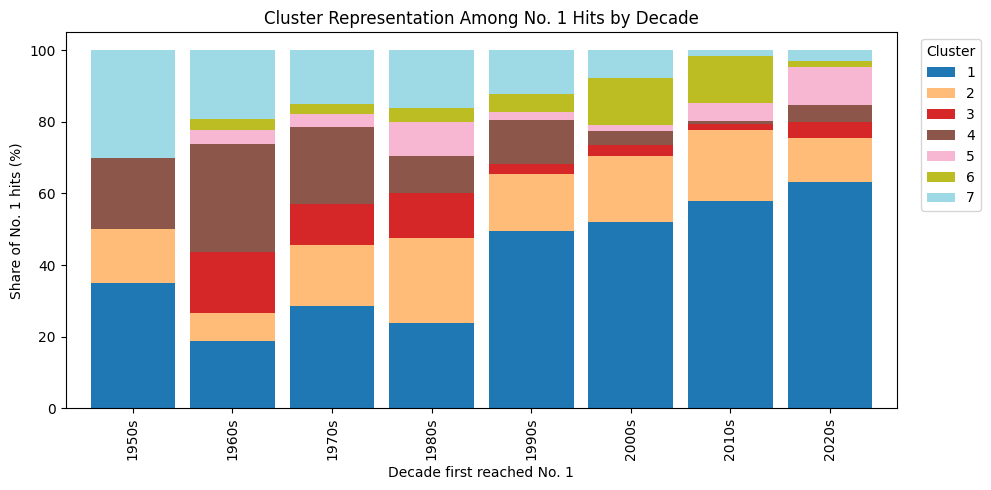

In [ ]:
# compare cluster representation by decade using row percentages.
observed = df.dropna(subset=['cluster', 'Date']).copy()
shares = pd.crosstab(observed['decade'], observed['cluster'], normalize='index') * 100
shares = shares.sort_index()
print('Percentage of No. 1 songs in each cluster within each decade:')
display(shares.round(1))

ax = shares.plot(kind='bar', stacked=True, figsize=(10, 5), width=.85, colormap='tab20')
ax.set_title('Cluster Representation Among No. 1 Hits by Decade')
ax.set_xlabel('Decade first reached No. 1')
ax.set_ylabel('Share of No. 1 hits (%)')
ax.legend(title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

Change in cluster representation between two full decades:


,1960s_pct,2010s_pct,change_pp
cluster,,,
1,18.8,57.8,38.9
2,7.9,19.8,11.9
3,16.8,1.7,-15.1
4,30.2,0.9,-29.3
5,4.0,5.2,1.2
6,3.0,12.9,10.0
7,19.3,1.7,-17.6


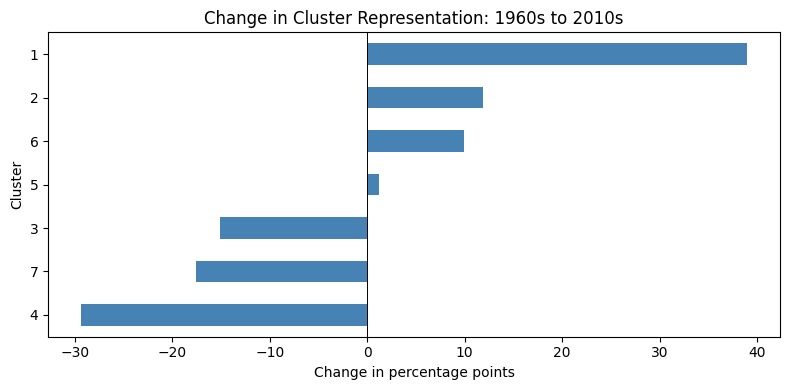

In [ ]:
# comparing the decades
comparison_decades = shares.loc[['1960s', '2010s']]
change = (comparison_decades.loc['2010s'] - comparison_decades.loc['1960s']).sort_values()
period_comparison = pd.DataFrame({
    '1960s_pct': comparison_decades.loc['1960s'],
    '2010s_pct': comparison_decades.loc['2010s'],
    'change_pp': comparison_decades.loc['2010s'] - comparison_decades.loc['1960s'],
}).round(1)
print('Change in clusters between the two decades:')
display(period_comparison)

ax = change.plot.barh(figsize=(8, 4), color='steelblue')
ax.axvline(0, color='black', linewidth=0.7)
ax.set_title('Change in Clusters: 1960s to 2010s')
ax.set_xlabel('Change in percentage points')
ax.set_ylabel('Cluster')
plt.tight_layout()
plt.show()

## 8. Unused fields

The overall dataset contained over 100 fields. I chose to select some of the fields that were not used in the clustering to see if the groupings also differ in some of these fields that were not baked into the algorithm showing that there are broader relationships in the clustering groups created.

In [ ]:
def count_credits(value):
    if pd.isna(value) or not str(value).strip():
        return np.nan
    names = [name.strip() for name in str(value).split(';') if name.strip()]
    names = [name for name in names if name.casefold() not in {'unknown', 'none', 'n/a'}]
    return len(names) if names else np.nan

df['songwriter_count'] = df['Songwriters w/o Interpolation & Sample Credits'].apply(count_credits)
df['producer_count'] = df['Producers'].apply(count_credits)

# weeks at No. 1.
external = (df.dropna(subset=['cluster'])
            .groupby('cluster')
            .agg(songs=('Song', 'size'),
                 median_songwriters=('songwriter_count', 'median'),
                 median_producers=('producer_count', 'median'),
                 median_length_seconds=('Length (Sec)', 'median'),
                 mean_weeks_no_1=('Weeks at Number One', 'mean'),
                 sample_pct=('Sample', lambda s: 100 * s.eq(1).mean()),
                 cover_pct=('Cover', lambda s: 100 * s.eq(1).mean()),
                 interpolation_pct=('Interpolation', lambda s: 100 * s.eq(1).mean())))
print('Withheld recording and chart characteristics by cluster:')
display(external.round(1))

# leading labels per cluster.
for cluster_id in range(1, k + 1):
    subset = df[df['cluster'] == cluster_id]
    print(f'\nCluster {cluster_id}: most common individual record labels')
    display(subset['Label'].value_counts().head(5))

Withheld recording and chart characteristics by cluster:


,songs,median_songwriters,median_producers,median_length_seconds,mean_weeks_no_1,sample_pct,cover_pct,interpolation_pct
cluster,,,,,,,,
1,416,2.0,2.0,226.0,3.2,11.5,4.8,15.4
2,194,2.0,2.0,227.0,3.2,13.4,6.7,12.9
3,105,2.0,1.0,220.0,2.5,3.8,10.5,11.4
4,170,2.0,1.0,199.5,2.5,2.9,28.8,3.5
5,57,2.0,2.0,232.0,2.7,1.8,10.5,8.8
6,62,3.0,1.0,230.5,3.7,8.1,0.0,12.9
7,151,2.0,1.0,213.0,2.6,2.0,31.1,4.6



Cluster 1: most common individual record labels


,count
Label,
Columbia,56
RCA,25
Capitol,18
Epic,16
Jive,12



Cluster 2: most common individual record labels


...

,count
Label,
Columbia,13
Epic,8
RCA,7
XO;Republic,3
A&M,2



Cluster 6: most common individual record labels


,count
Label,
Interscope,4
SBK,3
Shady;Aftermath,3
Republic,3
A&M Octone,3



Cluster 7: most common individual record labels


,count
Label,
RCA,15
Columbia,14
Arista,14
MCA,9
Epic,9


## 9. Saving all songs within clusters

In [ ]:
# one export, not multiple manually maintained datasets.
output_file = 'cluster assignments.csv'
df.to_csv(output_file, index=False)
print(f'Saved {len(df):,} songs to {output_file}')
print('Clustered:', df['cluster'].notna().sum(), 'Excluded:', df['cluster'].isna().sum())

# shows the first 25 songs from the cluster chose in in cluster_to_view variable
cluster_to_view = 1
cols_to_view = ['Song', 'Artist', 'Date', 'Discogs Genre', 'Artist Place of Origin',
                'Parent Label', 'Artist Structure', 'Label', 'Weeks at Number One']
cluster_view = df.loc[df['cluster'] == cluster_to_view, cols_to_view]
print(f'Cluster {cluster_to_view}: {len(cluster_view)} songs. To see all rows, use display(cluster_view).')
display(cluster_view.head(25))

Saved 1,177 songs to Billboard_No1_Industry_KModes_Assignments.csv
Clustered: 1155 Excluded: 22
Cluster 1: 416 songs. To see all rows, use display(cluster_view).


,Song,Artist,Date,Discogs Genre,Artist Place of Origin,Parent Label,Artist Structure,Label,Weeks at Number One
0,Poor Little Fool,Ricky Nelson,1958-08-04,Rock,United States,Imperial,1.0,Imperial,2
4,It's Only Make Believe,Conway Twitty,1958-11-10,Rock,United States,MGM,1.0,MGM,2
9,Stagger Lee,Lloyd Price,1959-02-02,Rock,United States,ABC,1.0,ABC-Paramount,4
12,The Happy Organ,"Dave ""Baby"" Cortez",1959-05-11,Rock,United States,Clock,1.0,Clock,1
13,Kansas City,Wilbert Harrison,1959-05-18,Rock,United States,Fury,1.0,Fury,2
15,Lonely Boy,Paul Anka,1959-07-13,Rock,Canada,ABC,1.0,ABC-Paramount,4
16,Big Hunk o' Love,Elvis Presley,1959-08-10,Rock,United States,RCA,1.0,RCA,2
23,El Paso,Marty Robbins,1960-01-04,"Pop;Folk, World, & Country",United States,CBS,1.0,Columbia,2
32,Itsy Bitsy Teenie Weenie Yellow Polka Dot Bikini,Brian Hyland,1960-08-08,Rock,United States,Kapp,1.0,Leader,1
33,It's Now or Never,Elvis Presley,1960-08-15,Rock,United States,RCA,1.0,RCA,5
